# 🫀 Praktikum: Heart Classification (Multi-Layer Perceptron)

Notebook ini berisi implementasi Multi-Layer Perceptron (MLP) untuk melakukan klasifikasi penyakit jantung (Heart Classification) menggunakan data dari UCI Statlog. Eksperimen mencakup variasi jumlah *hidden layer*, *learning rate* ($\mu$), dan *epoch* sesuai dengan penugasan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier as MLP
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import warnings

warnings.filterwarnings('ignore')

# List untuk menampung semua hasil eksperimen agar bisa dirangkum di akhir
all_results = []

Mengimpor pustaka yang dibutuhkan. `pandas` dan `numpy` untuk manipulasi data, `matplotlib` untuk visualisasi, `MLPClassifier` untuk model jaringan saraf, dan `StandardScaler` untuk normalisasi data agar konvergensi gradient descent lebih optimal.

In [2]:
# Membaca dataset
dataset = pd.read_csv('D:/CODE/Neuro Computing/Data/heart.csv')

# Memisahkan fitur (data) dan target (label)
X = dataset.iloc[:, 0:-1]
y = dataset.iloc[:, -1]

# Normalisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dimensi dataset:", dataset.shape)
dataset.head()

Dimensi dataset: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Data dimuat dari `heart.csv`. Sesuai dengan instruksi, **evaluasi dilakukan menggunakan seluruh data pelatihan** (tidak ada *train-test split*). Data fitur (`X`) dinormalisasi menggunakan `StandardScaler` (Z-score) untuk menghindari masalah perbedaan skala antar fitur klinis (seperti usia dan detak jantung).

Score (Accuracy): 0.9042904290429042


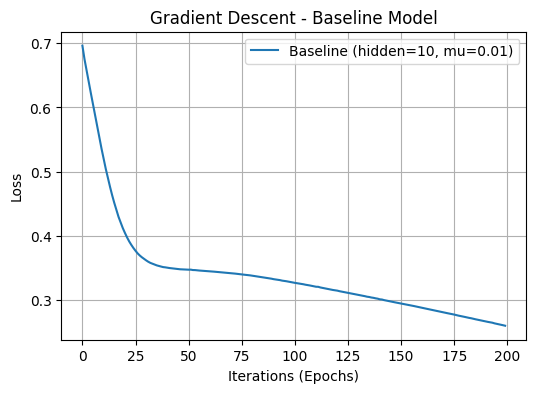

In [3]:
# Model Baseline
model_base = MLP(tol=0, hidden_layer_sizes=(10,), activation='logistic', learning_rate_init=0.01)
model_base.fit(X_scaled, y)

# Evaluasi Baseline
y_pred_base = model_base.predict(X_scaled)
print('Score (Accuracy):', model_base.score(X_scaled, y))

# Plot Loss Curve
plt.figure(figsize=(6,4))
plt.plot(model_base.loss_curve_, label='Baseline (hidden=10, mu=0.01)')
plt.xlabel('Iterations (Epochs)')
plt.ylabel('Loss')
plt.title('Gradient Descent - Baseline Model')
plt.legend()
plt.grid(True)
plt.show()

Membuat **Baseline Model** sebagai langkah awal. Model dikonfigurasi dengan 10 *hidden units*, fungsi aktivasi *logistic* (sigmoid), dan $\mu=0.01$. Terlihat bahwa *loss* mengalami penurunan seiring bertambahnya iterasi (epoch).

## 🧪 Eksperimen 1: Variasi Jumlah *Hidden Layer* (Neuron)
Melakukan eksperimen menggunakan $\mu=0.1$ dengan jumlah neuron pada *hidden layer* bervariasi: **5, 10, 15, 20, dan 25**.

Hidden     | Accuracy   | Precision  | Recall     | F1-Score  
------------------------------------------------------------
5          | 0.9571     | 0.9524     | 0.9697     | 0.9610    
10         | 0.9901     | 0.9880     | 0.9939     | 0.9909    
15         | 1.0000     | 1.0000     | 1.0000     | 1.0000    
20         | 1.0000     | 1.0000     | 1.0000     | 1.0000    
25         | 1.0000     | 1.0000     | 1.0000     | 1.0000    


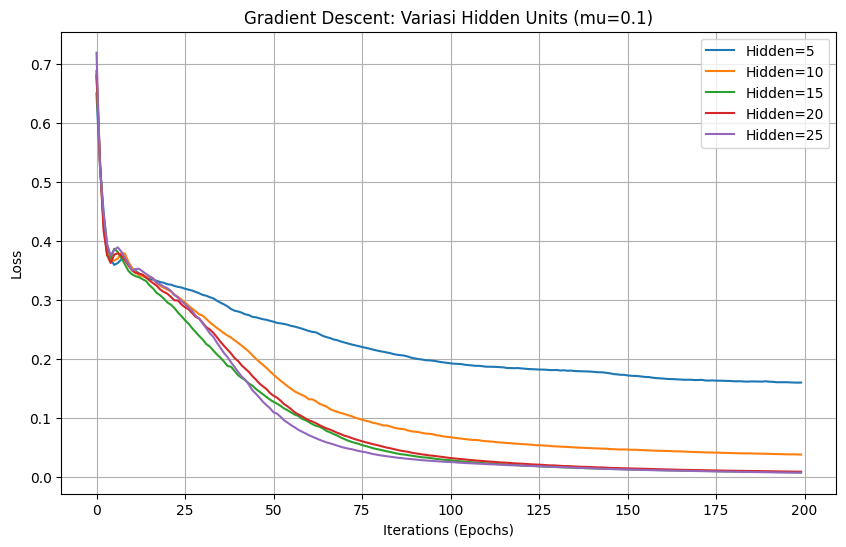

In [4]:
hidden_layers = [5, 10, 15, 20, 25]
mu = 0.1

plt.figure(figsize=(10,6))
print(f"{'Hidden':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 60)

for h in hidden_layers:
    # Inisialisasi dan pelatihan model
    model = MLP(tol=0, hidden_layer_sizes=(h,), activation='logistic', learning_rate_init=mu)
    model.fit(X_scaled, y)
    
    # Prediksi & Perhitungan Metrik
    y_pred = model.predict(X_scaled)
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred)
    rec = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    
    # Simpan hasil untuk tabel akhir
    all_results.append({'Eksperimen': '1 (Hidden Units)', 'Parameter': f'Hidden={h}, mu={mu}', 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})
    
    # Tampilkan metrik
    print(f"{h:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")
    
    # Tambahkan kurva loss ke plot
    plt.plot(model.loss_curve_, label=f'Hidden={h}')

plt.xlabel('Iterations (Epochs)')
plt.ylabel('Loss')
plt.title('Gradient Descent: Variasi Hidden Units (mu=0.1)')
plt.legend()
plt.grid(True)
plt.show()

## 🧪 Eksperimen 2: Variasi *Learning Rate* ($\mu$)
Melakukan eksperimen menggunakan *hidden layer* = 10 dengan nilai $\mu$ bervariasi: **0.01, 0.05, 0.1, 0.5, dan 1**.

Learning Rate   | Accuracy   | Precision  | Recall     | F1-Score  
-----------------------------------------------------------------
0.01            | 0.9010     | 0.8947     | 0.9273     | 0.9107    
0.05            | 0.9901     | 0.9880     | 0.9939     | 0.9909    
0.1             | 0.9868     | 0.9879     | 0.9879     | 0.9879    
0.5             | 0.9736     | 0.9876     | 0.9636     | 0.9755    
1               | 0.9604     | 0.9422     | 0.9879     | 0.9645    


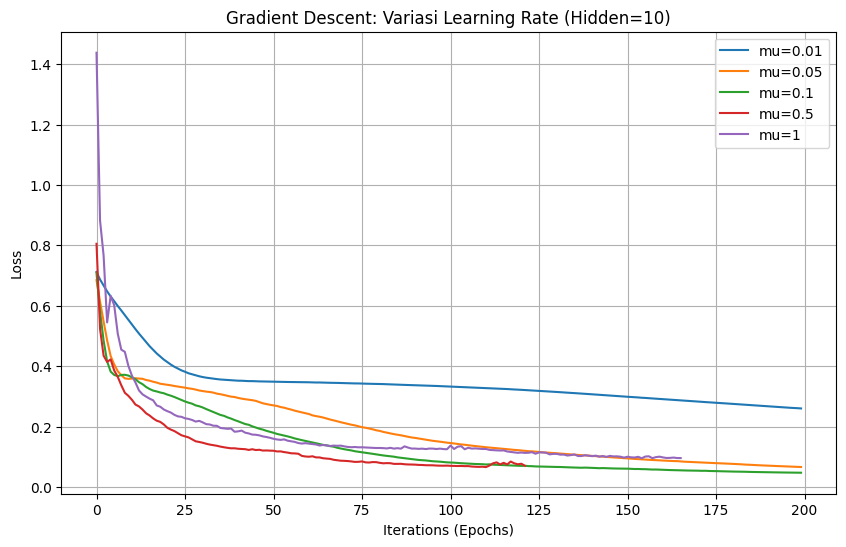

In [5]:
learning_rates = [0.01, 0.05, 0.1, 0.5, 1]
hidden = 10

plt.figure(figsize=(10,6))
print(f"{'Learning Rate':<15} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 65)

for lr in learning_rates:
    # Inisialisasi dan pelatihan model
    model = MLP(tol=0, hidden_layer_sizes=(hidden,), activation='logistic', learning_rate_init=lr)
    model.fit(X_scaled, y)
    
    # Prediksi & Perhitungan Metrik
    y_pred = model.predict(X_scaled)
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred)
    rec = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    
    # Simpan hasil untuk tabel akhir
    all_results.append({'Eksperimen': '2 (Learning Rate)', 'Parameter': f'Hidden={hidden}, mu={lr}', 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})
    
    # Tampilkan metrik
    print(f"{lr:<15} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")
    
    # Tambahkan kurva loss ke plot
    plt.plot(model.loss_curve_, label=f'mu={lr}')

plt.xlabel('Iterations (Epochs)')
plt.ylabel('Loss')
plt.title('Gradient Descent: Variasi Learning Rate (Hidden=10)')
plt.legend()
plt.grid(True)
plt.show()

## 🧪 Eksperimen 3: Variasi *Epoch* (Max Iterations)
Melakukan eksperimen dengan mengubah batas maksimal epoch (iterasi) untuk mengamati performa awal hingga konvergensi. Konfigurasi yang digunakan: **$\mu=0.1$, *hidden layer*=10**, dengan variasi epoch: **50, 100, 200, 500, dan 1000**.

Epochs     | Accuracy   | Precision  | Recall     | F1-Score  
------------------------------------------------------------
50         | 0.9439     | 0.9458     | 0.9515     | 0.9486    
100        | 0.9802     | 0.9704     | 0.9939     | 0.9820    
200        | 0.9934     | 0.9939     | 0.9939     | 0.9939    
500        | 0.9967     | 0.9940     | 1.0000     | 0.9970    
1000       | 0.9901     | 0.9939     | 0.9879     | 0.9909    


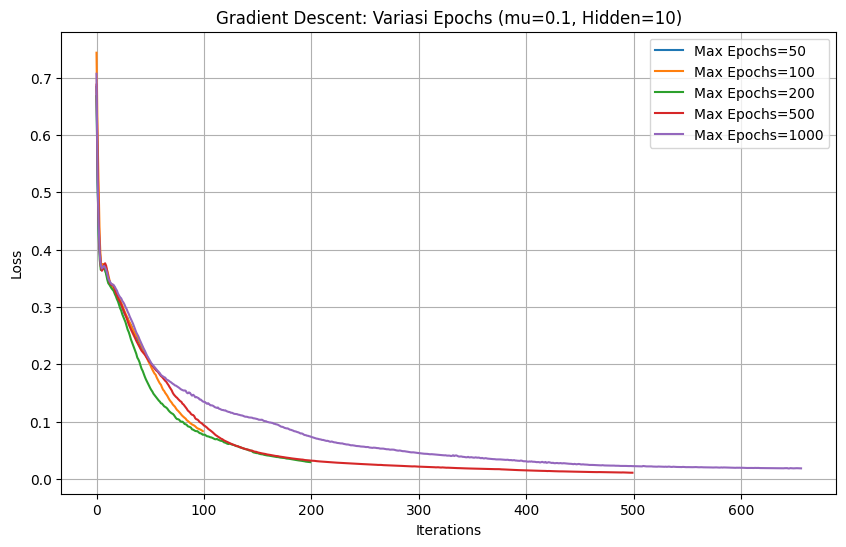

In [6]:
epochs = [50, 100, 200, 500, 1000]
mu = 0.1
hidden = 10

plt.figure(figsize=(10,6))
print(f"{'Epochs':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 60)

for ep in epochs:
    # Inisialisasi dan pelatihan model dengan batas max_iter
    model = MLP(tol=0, hidden_layer_sizes=(hidden,), activation='logistic', learning_rate_init=mu, max_iter=ep)
    model.fit(X_scaled, y)
    
    # Prediksi & Perhitungan Metrik
    y_pred = model.predict(X_scaled)
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred)
    rec = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    
    # Simpan hasil untuk tabel akhir
    all_results.append({'Eksperimen': '3 (Epochs)', 'Parameter': f'Epoch={ep}', 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})
    
    # Tampilkan metrik
    print(f"{ep:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")
    
    # Tambahkan kurva loss ke plot
    plt.plot(model.loss_curve_, label=f'Max Epochs={ep}')

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Gradient Descent: Variasi Epochs (mu=0.1, Hidden=10)')
plt.legend()
plt.grid(True)
plt.show()

## 📊 Rangkuman Keseluruhan Eksperimen
Berikut adalah tabel konsolidasi dari seluruh eksperimen yang menampilkan tingkat *Accuracy*, *Precision*, *Recall*, dan *F1-score* untuk masing-masing konfigurasi.

In [7]:
# Membuat DataFrame dari seluruh hasil yang dikumpulkan
df_results = pd.DataFrame(all_results)

# Format metrik sebagai persentase agar lebih mudah dibaca (opsional)
df_results['Accuracy'] = (df_results['Accuracy'] * 100).map('{:.2f}%'.format)
df_results['Precision'] = (df_results['Precision'] * 100).map('{:.2f}%'.format)
df_results['Recall'] = (df_results['Recall'] * 100).map('{:.2f}%'.format)
df_results['F1-Score'] = (df_results['F1-Score'] * 100).map('{:.2f}%'.format)

# Tampilkan tabel
display(df_results)

,Eksperimen,Parameter,Accuracy,Precision,Recall,F1-Score
0,1 (Hidden Units),"Hidden=5, mu=0.1",95.71%,95.24%,96.97%,96.10%
1,1 (Hidden Units),"Hidden=10, mu=0.1",99.01%,98.80%,99.39%,99.09%
2,1 (Hidden Units),"Hidden=15, mu=0.1",100.00%,100.00%,100.00%,100.00%
3,1 (Hidden Units),"Hidden=20, mu=0.1",100.00%,100.00%,100.00%,100.00%
4,1 (Hidden Units),"Hidden=25, mu=0.1",100.00%,100.00%,100.00%,100.00%
5,2 (Learning Rate),"Hidden=10, mu=0.01",90.10%,89.47%,92.73%,91.07%
6,2 (Learning Rate),"Hidden=10, mu=0.05",99.01%,98.80%,99.39%,99.09%
7,2 (Learning Rate),"Hidden=10, mu=0.1",98.68%,98.79%,98.79%,98.79%
8,2 (Learning Rate),"Hidden=10, mu=0.5",97.36%,98.76%,96.36%,97.55%
9,2 (Learning Rate),"Hidden=10, mu=1",96.04%,94.22%,98.79%,96.45%
